# 📊 What is "Typical"? An Introduction to Center and Spread

<div class="alert alert-info">
Welcome back! In this notebook, we will explore how to measure the <strong>center</strong> and <strong>spread</strong>  of a dataset. and how visualizations can give insight into what is "typical".
</div>

When we have any collection of measurements, we have a **distribution**. How can we summarize a whole set of data with just a few numbers? 

<hr style="border: 5px solid #003262;" />

### 🔸 Key Ideas in Describing Center and Spread

When working with data, a collection of measurements is called a **distribution**. Notebooks are the perfect environment to explore the "shape" of that data, through visualizing data and even adding values to a dataset to explore how the impact the whole.

**Our Learning Goals:**
* **Managing Lists and Dataframes:** Using `list` or `dataframe` to store and manipulate data, and filter to focus on relevant records.

* **Exploring Center and Spread:** Using `mean`, `median`, standard deviation, range, interquartile range, percentiles, and outliers to reason about typicality. Exploring the "shape" of data using `histograms` and `boxplots`.

* **Content:** Applying these statistical concepts to explore patterns in classroom test scores and housing prices.

Let's start with a simple, common scenario as a teacher: imagine you have a set of student test scores from a quiz graded out of 100 points.

---

### 🔸 Part I: Loading the Data

We'll start with a simple list of hypothetical test scores. We store these numbers as a `list` by putting them in brackets, making it easy to change values and test what happens. 

In [ ]:
# Define our list of test scores.
scores = [85, 51, 78, 88, 95, 81, 55, 89, 90, 84]
scores

<div class="alert alert-success">

**Considering the data above…**

* What would you describe as a "typical" score on this test, given the list above?

* How would you change the list (if at all) to create different teaching scenarios? For example, how would these scores look for a test that was especially difficult? For a diagnostic pre-test where you expect students to have very different levels of preparation?

We'll use this list to practice coding and creating visualizations.  

As always, we'll model good documentation: explaining the **why** (in text) and the **how** (in `# code comments`).  

---

### 🔸 Part II: Describing the data

Let's explore different ways to describe this list of scores. We'll start with two ways to describe what is a _typical_ score: the **mean** (average) and the **median** (middle value when sorted).

The mean is calculated by getting the sum total of our scores divided by the number of scores.

We can get the sum total of the scores by calling the built-in Python function `sum()`.

To see how many values are within our list, or the number of quiz scores we have, we can use the `len()` function to count the number of values in our list.

In [ ]:
print(f"Sum total of scores is: {sum(scores)}")
print(f"Number of scores in our list: {len(scores)}")

avg_score_manual = sum(scores)/len(scores)
print(f"Average test score: {avg_score_manual}")

The median is the middle number in our test scores. However, currently our list `scores` is not in an order to manually calculate the median because we need the values in order from lowest to greatest to see what the middle value is. In order to get them in this order, we will need to use the `sort()` function for our list.

We also have an issue because we have 10 quiz scores so we need to include another step to get the median value for our scores. 

The extra step is that we must get the average of the two inner values in our sorted list. 

In [ ]:
scores.sort() # reorder scores from lowest to highest
print(f"Sorted order of quiz scores: {scores}")

middle_two_scores = [84, 85]
print(f"The two middle scores are: {middle_two_scores}")

median_score_manual = sum(middle_two_scores)/len(middle_two_scores)
print(f"The median of the quiz scores is: {median_score_manual}")

While we now understand how to calculate the mean and the median, the functions `np.mean()` and the `np.median()` from the numPy library make it a lot easier to calculate both scores. 

In [ ]:
import numpy as np

# The lines below calculate the mean and median of the scores list.
mean_score = np.mean(scores) 
median_score = np.median(scores) 

# The lines below each output a label, followed by the corresponding value.
print(f"Mean: {mean_score}")  
print(f"Median: {median_score}") 

<div class="alert alert-success">

**Considering the results above…**

* Would you say the mean or the median is more "typical" of this class' performance on the test? Why?

* How would you explain the difference between these two values? What do they tell you about more general patterns in the data?

Now, let's describe the _spread_ of scores, or how far the scores tend to vary from the mean/median.

The first measures of spread that we will cover are the minimum and maximum values. These values correspond to the lowest and greatest value **in our data**. For example, if we are interested in adults (18 to 65+), but our data only contains data from 18 to 57 then our minimum value would be 18 and our maximum would be 57.

We will use the `np.min()` and `np.max()` functions from the numPy package to get these values. These values are important because we can then calculate the range, or the distance between the lowest and greatest values in our data.

In [ ]:
# Calculate the min and max of the scores.
min_score = np.min(scores)
max_score = np.max(scores) 
range_of_scores = max_score - min_score

# Output the labels and corresponding values.
print(f"Min: {min_score}")  
print(f"Max: {max_score}") 
print(f"Range: {range_of_scores}")


There are measures of spread that are more often used with either the mean or median of our data.

When using the mean, it is common to use either variance, using the `np.var()` function in NumPy, or standard deviation, using the `np.std()` function from NumPy, to see the spread of scores. The variance shows the distance that scores are from the mean in squared units.

Since this is not very helpful for interpretation, we can get the square root of the variance to get the standard deviation, which shows the distance that scores are from the mean in the same units as the values used to calculate the mean.

In our quiz scores example, the variance would indicate how far scores differ from the mean in squared points whie the standard deviation would indicate how far scores differ from the mean in points.

*Note*: Both the variance and standard deviation could be used with the median to show the spread around the median instead of the mean.

In [ ]:
# Calculate the variance and standard deviation of the scores.
var_score = np.var(scores)
std_dev_score = np.std(scores)

# Round the standard deviation to two decimal places.
var_score = round(var_score, 2)
std_dev_score = round(std_dev_score, 2)

# Output the labels and corresponding values.
print(f"Variance: {var_score}")
print(f"Standard Deviation: {std_dev_score}") 

For the median, we need to calculate additional values to get other measures of spread. We need to calculate the percentiles for the 25th and 75th percentiles. Since the median is always the middle of the distribution, it is also the 50th percentile. We can use the `np.percentile()` function from NumPy to get any percentile we want. In this case, we'll get the 25th and 75th percentiles for our purposes. 

We want the 25th and 75th percentiles because we want to calculate the *interquartile range*. We previously calculated the range, which was the distance from the maximum score in our data to the minimum score. The interquartile range, also referred to as IQR, is the distance from the 75th percentile, also called q3 for quartile 3, to the 25th percentile, also referred to as q1 for quartile 1.

In [ ]:
# Calculate the percentiles for the 25th, 50th and 75th percentiles of the scores.
q1 = np.percentile(scores, 25)
q2 = np.percentile(scores, 50)
q3 = np.percentile(scores, 75)

# Calculate the interquartile range
iqr = q3 - q1

# Output the labels and corresponding values.
print(f"25th percentile: {q1}")
print(f"50th percentile: {q2}")
print(f"Median: {median_score}")
print(f"75th percentile: {q3}")
print(f"Interquartile range: {iqr}")

<div class="alert alert-success">

**Considering the results above…**

* How would you explain the standard deviation? 

* What is the standard deviation's relationship to the maximum and minimum values? What does it tell you about what's "typical" in this group of scores?

* What would be an example of an "atypical" or outlier score for this list based on the multiple measures of spread above?

---

### 🔸 Part III: Visualizing the Data

Values like the mean, median, and standard deviation give quick summaries, but visualization helps us see the overall "shape" of the data. Let's look at the distribution of test scores.

In [ ]:
import seaborn as sns # seaborn is for making beautiful plots

# this library gives you more control over plotting functions
import matplotlib.pyplot as plt 

# Create a histogram of scores.
sns.histplot(scores, bins=10)
plt.xlim(0, 100)

We can also use the 25th and 75th percentile values to explore our data for outliers. Using the 25th and 75th percentiles, we can either subtract or add the product of the IQR and 1.5 to see what is the lowest or greatest value before a score is considered an outlier.

These are the "whiskers" used in boxplots to visualize distributions. Below is code to calculate the whiskers and create a boxplot of the same list of scores.

In [ ]:
# Calculate the "whiskers" to look for outliers/extreme values
lower_whisker = q1 - 1.5 * iqr
upper_whisker = q3 + 1.5 * iqr

# Corrections to get accurate whisker values
wisklo = np.compress(scores >= lower_whisker, scores)
wiskhi = np.compress(scores <= upper_whisker, scores)
actual_loval = np.min(wisklo)
actual_hival = np.max(wiskhi)

# Output the labels and corresponding values.
print(f"Lowest value before outliers: {actual_loval}")
print(f"Greatest value before outliers: {actual_hival}")

In [ ]:
sns.boxplot(scores, orient = 'h')
plt.xlim(0, 100)

<div class="alert alert-success">

**Looking at the histogram and boxplot above...**

* What do you pay attention to when thinking about what a "typical" test score is in this list of scores?

* What is easier, and harder, to understand or describe when you are using the plots versus when you are using values like the mean, median, standard deviation, range, percentiles, and interquartile range?

---

### 🔸 Part IV: Exploring Different Distributions

Since our data will often have more than 10 values, let's examine quiz score data for 1,000 students. 

For our example below, let's focus on a quiz where the majority of students do well on the quiz.

<a id="set-scores"></a>

<div class="alert alert-success">

**Before running the following code**

* What do you think will happen to the **mean**, **median**, and **measures of spread** in this scenario?

In [ ]:
np.random.seed(12345)
# creates a distribution
new_scores = np.random.beta(a=14, b=1.5, size=1000) * 100
# clip is to make sure no student gets below a 0 and over 100
new_scores = np.clip(new_scores, 0, 100)

new_mean = np.mean(new_scores)
new_median = np.median(new_scores)

print(f"Mean: {new_mean}")
print(f"Median: {new_median}")
print(f"Standard Deviation: {round(np.std(new_scores), 2)}")

In [ ]:
sns.histplot(new_scores)
# We'll include the whole scale for exam scores
plt.xlim(0, 100)

You can add lines to indicate where the `new_mean` and `new_median` that you calculated above lie in the distribution of scores. Use and adapt the code example below to add lines to the plot above.

```
# plt.axvline(new_mean, color='red', linestyle='--', label=f'Mean ({new_mean:.2f})')
# plt.axvline(new_median, color='orange', linestyle='-', label=f'Median ({new_median:.2f})')
# plt.legend()
```

In [ ]:
sns.boxplot(new_scores, orient = 'h')
plt.xlim(0, 100)

<div class="alert alert-success">

**As you explore, consider...**

* How do the mean, median, and the measures of spread help you understand the differences between different kinds of distributions?  

* What features of a dataset seem important to understand before describing a "typical" part of the data?

* What information might still be "hidden" by these statistics, and how can plots help you learn more?

### Choose at least one scenario to test

Change the values in the `np.random.beta` distribution to see how the distribution changes and how the mean, median, and measures of spread change in each scenario. [Click here to go back to the distribution.](#set-scores)



## **Summary:** 

You now know how to describe a collection of measurements using `mean`, `median`, `and measures of spread`, and different types of plots. You should also have an idea about what these methods can and cannot tell you about the true "shape" of a dataset.

Now, we'll apply these skills to a real dataset. 

<hr style="border: 5px solid #003262;" />

# 🏠 Keeping it Real (Estate): Exploring Typical Housing Prices in Atypical Markets

We'll explore housing prices in South Lake Tahoe, CA. This city has a mixture of residential and vacation homes, which makes it difficult to describe what a "typical" home price is in this area.

<div style="display: flex; justify-content: space-around;">
<br/>

<img src="https://github.com/CalCoRE/show-your-work/blob/typicality/images/lakeside.jpg?raw=true" height="150"> 
<br/>

<img src="https://github.com/CalCoRE/show-your-work/blob/typicality/images/roadside.jpg?raw=true" height="150"> 
<br/>

<img src="https://github.com/CalCoRE/show-your-work/blob/typicality/images/snowy.jpg?raw=true" height="150"> 
<br/>

</div>
<br/>

You'll then have an opportunity to compare our findings with other cities that you choose.

---

### 🔸 Part I: Loading and Filtering the Data

We'll start by loading and previewing the dataset. Our data comes from 2021-2022 home sales listings across the United States from realtor.com.

Before running the next cell, think about what you might expect to see in our national home sales dataset.

In [46]:
import pandas as pd

all_housing = pd.read_csv('https://github.com/CalCoRE/show-your-work/blob/typicality/data/sold-realtor-data.csv?raw=true')

all_housing

,price,bed,bath,acre_lot,city,state,zip_code,house_size,prev_sold_date
0,77500.0,3.0,1.0,NaN,Ponce,Puerto Rico,717.0,957.0,2021-11-29
1,524900.0,3.0,2.0,0.09,Aguada,Puerto Rico,602.0,2200.0,2021-12-13
2,175000.0,NaN,NaN,0.14,Aguadilla,Puerto Rico,603.0,3200.0,2021-11-29
3,90000.0,3.0,2.0,0.08,Aguadilla,Puerto Rico,603.0,1421.0,2021-10-19
4,22500.0,2.0,1.0,0.32,Anasco,Puerto Rico,610.0,850.0,2021-12-30
...,...,...,...,...,...,...,...,...,...
812004,359900.0,4.0,2.0,0.33,Richland,Washington,99354.0,3600.0,2022-03-25
812005,350000.0,3.0,2.0,0.10,Richland,Washington,99354.0,1616.0,2022-03-25
812006,440000.0,6.0,3.0,0.50,Richland,Washington,99354.0,3200.0,2022-03-24
812007,179900.0,2.0,1.0,0.09,Richland,Washington,99354.0,933.0,2022-03-24


We'll focus on homes sold in South Lake Tahoe, CA. Below, we create a new dataset called `my_housing` that filters the full dataset by state and city. We use both because there are often cities with the same name in different states.

You'll have a chance to come back later and try this with other subsets of the data.

<a id="set-housing-data"></a>

In [47]:
# Filter the all_housing dataset by state to create a new dataset called my_housing.
my_housing = all_housing[all_housing['state'] == 'California']

# Further filter my_housing by city.
my_housing = my_housing[my_housing['city'] == 'South Lake Tahoe']

my_housing

,price,bed,bath,acre_lot,city,state,zip_code,house_size,prev_sold_date
634101,539000.0,3.0,2.0,0.21,South Lake Tahoe,California,96150.0,1329.0,2021-11-10
634117,395000.0,2.0,1.0,0.11,South Lake Tahoe,California,96150.0,876.0,2021-11-12
634162,525000.0,3.0,2.0,0.12,South Lake Tahoe,California,96150.0,1380.0,2021-11-12
634170,559000.0,3.0,1.0,0.24,South Lake Tahoe,California,96150.0,1144.0,2021-11-15
634173,499900.0,3.0,2.0,0.12,South Lake Tahoe,California,96150.0,1032.0,2021-11-15
...,...,...,...,...,...,...,...,...,...
763470,459400.0,3.0,1.0,0.12,South Lake Tahoe,California,96150.0,1160.0,2022-03-07
763471,948000.0,6.0,6.0,NaN,South Lake Tahoe,California,96150.0,3757.0,2022-03-07
763476,850000.0,4.0,3.0,0.14,South Lake Tahoe,California,96150.0,1956.0,2022-04-22
763484,959000.0,4.0,3.0,0.21,South Lake Tahoe,California,96150.0,1824.0,2021-11-23


<div class="alert alert-success">

**Examine the data table previewed above…**


* What do you notice and wonder about this dataset?


* What do you predict the mean home price in South Lake Tahoe, CA to be? Why?

---

### 🔸 Part II: Describing Center and Spread

In the first activity, we used a list of values. Here, information is stored as a dataframe, but we can treat specific columns similarly using the column name like `my_housing["price"]`. 

Let's use the same tools to explore home sales prices from South Lake Tahoe, CA. We'll start by looking at the minimum and maximum home sale prices.

In [50]:
min_price = my_housing["price"].min()
max_price = my_housing["price"].max()

# The lines below each output a label, followed by the corresponding value.
print(f"Min: {min_price}")  
print(f"Max: {max_price}") 

Min: 42000.0
Max: 13500000.0


<div class="alert alert-success">

**Considering the values above…**


* Do these values seem reasonable, given what you know about South Lake Tahoe? Why or why not?


* Would you say that knowing the maximum and minimum home prices can help you describe what a "typical" home price is in this area? Why or why not?


* Do you expect the mean or median home price to be higher? Why?

Now, let's look at the mean, median, and standard deviation of home prices in South Lake Tahoe, CA.

In [52]:
mean_price = np.mean(my_housing['price'])
median_price = np.median(my_housing['price'])
stdev_price = np.std(my_housing['price'])

mean_price = round(mean_price, 2)
stdev_price = round(stdev_price, 2)

print(f"Mean Price: {mean_price}")
print(f"Median Price: {median_price}")
print(f"Standard Deviation of Prices: {stdev_price}")


Mean Price: 852939.36
Median Price: 635000.0
Standard Deviation of Prices: 992926.05


<div class="alert alert-success">

**Considering the results above…**


* Are the mean, median, and standard deviation what you expected? Why or why not?



* Can you explain why the mean price for homes in South Lake Tahoe, CA is higher than the median price?



* Would you say a home price of \(\$750,000\)
 is "typical" for South Lake Tahoe? What about \(1.5M\)? Why or why not?





* How would you explain the standard deviation shown above to a student?

---

### 🔸 Part III: Visualizing the Data

We've seen the dramatic effects that extreme outliers can have on a dataset. But it might still be difficult to get a full sense of what's a "typical" price in this area. Let's use visualization to dig a little deeper.

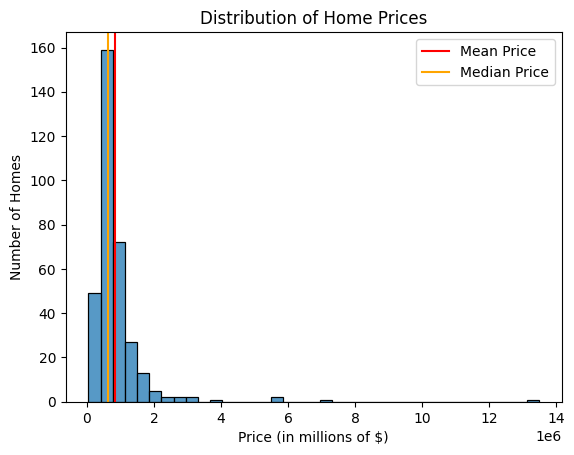

In [58]:
# Create a histogram of home prices.
sns.histplot(my_housing, x = 'price', edgecolor = 'black')

# Add vertical lines for the mean and median prices.
plt.axvline(mean_price, color='red', label='Mean Price')
plt.axvline(median_price, color='orange', label='Median Price')

# Format the x-axis to show prices in millions.
plt.ticklabel_format(style='sci', scilimits=(6, 6), axis='x')

# Add titles and labels.
plt.title('Distribution of Home Prices')
plt.xlabel('Price (in millions of $)')
plt.ylabel('Number of Homes')
plt.legend()
plt.show()

Text(0.5, 0, 'Price (in millions of $)')

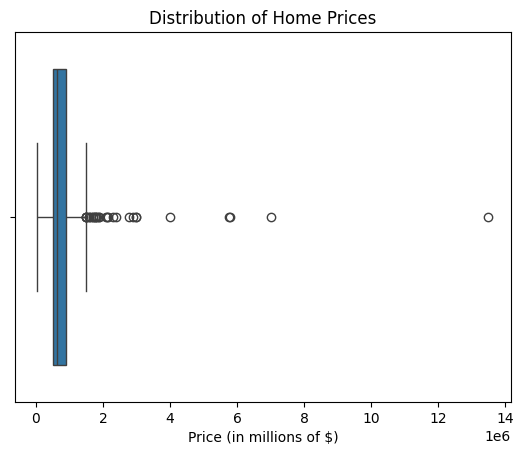

In [62]:
sns.boxplot(my_housing, x = 'price', orient = 'h')
plt.ticklabel_format(style='sci', scilimits=(6, 6), axis='x')
plt.title('Distribution of Home Prices')
plt.xlabel('Price (in millions of $)')

<div class="alert alert-success">

**Looking at the visualization above…**


* Has your understanding of what a "typical" home price in South Lake Tahoe changed after seeing the histogram and boxplot? How or why not?



* Give some examples of what you would consider to be "typical," "borderline," and "atypical" home prices in this area, based on the visualizations above.

---

### 🔸 Part IV: Explore Other Collections of Housing Prices

We chose South Lake Tahoe, CA because it has an especially *skewed* distribution of home prices, with a few very expensive homes pulling the mean up well above the median. While this is a dramatic example, home prices are typically skewed in this way. This is why you often see the median home price reported in real estate listings or in the news, rather than the mean.

Think about other ways to explore the distribution of home prices. You might be interested in other `cities`, entire `states`, or other aspects of housing such as the number of `bedrooms` or `house_size`. 

Consider some combination of factors that would capture:
* a subset of homes where the mean and median prices are closer together,
* a subset of homes where the median price is higher than the mean,
* a subset of homes with a wide range of what you would call "typical" prices.

Choose at least one scenario to explore. Filter the dataset to reflect the patterns you expect, and use the code to test your predictions. [Click here to go back to the top of this section and get started.](#set-housing-data)

<hr style="border: 1px solid #fdb515;" />

## In the Classroom

The skills you just practiced—calculating mean vs. median and visualizing distributions with histograms—are critical in any field that deals with real-world data, because real-world data is rarely perfectly symmetrical.

**Where Else Do We See Skewed Data?**

* **Economics:** Individual income in a country is famously skewed. Most people earn a modest income, while a very few earn extremely high incomes, pulling the mean income far above the median.

* **Biology:** The number of offspring produced by individuals in a species is often skewed. Most individuals may have 1-2 offspring, while a few "super-reproducers" might have many, many more.

* **Internet & Social Media:** The number of "likes" or "shares" on a post is highly skewed. The vast majority of posts get very few interactions, while a tiny fraction go viral and get millions.

In all these cases, understanding the difference between mean and median, and being able to see the shape of the data with a histogram, is essential for drawing accurate conclusions.


<hr style="border: 1px solid #fdb515;" />

## Connections to K-12 Standards

The concepts in this notebook align with several key educational standards, providing a clear path for classroom integration.

### Common Core State Standards for Mathematics
* **6.SP.A.2 & 3:** Understand that a set of data collected to answer a statistical question has a distribution which can be described by its center, spread, and overall shape. Recognize that a measure of center for a numerical data set summarizes all of its values with a single number.

* **HSS.ID.A.1, 2, & 3:** Represent data with plots on the real number line (histograms). Use statistics appropriate to the shape of the data distribution to compare center (median, mean) of different data sets. Interpret differences in shape, center, and spread in the context of the data sets, accounting for possible effects of extreme data points (outliers).

### Next Generation Science Standards (NGSS)
* **Science and Engineering Practice 4: Analyzing and Interpreting Data:** This notebook provides a direct application of this practice, as students must analyze data using computational tools to describe a dataset and understand its variability.

* **Crosscutting Concept 3: Scale, Proportion, and Quantity:** Understanding measures of center and spread is fundamental to describing a system quantitatively. This is especially true when discussing the impact of outliers, which highlights the importance of scale.

<hr style="border: 1px solid #fdb515;" />

# Credits

This notebook was developed as part of "Show York Work" (SyW), a research and development project at UC Berkeley to introduce computational notebooks to K-12 educators.

The SyW team includes, in alphabetical order: Pavritha Arun Anand, Sun Young Ban, Chul Huang, JungMin Shin, Michelle Wilkerson, and Xiaoyue Zhang.

This specific notebook was written by Sun Young Ban and includes contributions from Michelle Wilkerson and JungMin Shin.

Creation of this notebook was done with the assistance of Google Gemini Pro 2.5.

The real estate dataset used here is a subset of the USA Real Estate Dataset shared by Ahmed Shahriar Sakib on kaggle.com (https://doi.org/10.34740/kaggle/ds/3202774).

The South Lake Tahoe Roadside photo is available in the public domain on [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:50_through_South_Lake_Tahoe_by_Mark_Miller.jpg) by Amadscientist/Mark James Miller

The Lakeside House in South Lake Tahoe photo is available under CC-BY 3.0 via [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:South_Lake_Tahoe,_CA_-_panoramio.jpg) (originally Panoramio) by donifirebg

Snowy House "Cricket" photo is available under CC-BY-NC-SA 2.0 by jillmotts/Jill Siegrist on [flickr](https://www.flickr.com/photos/amayu/401688703/in/photolist-iW3Y1s-2qRRg2r-2qRvTXC-2n7QgNz-2n7G3oM-2mwhieU-eKq9zK-6QPQR-44Kp99-w7EPhU-DMmv1B-xeMnvT-2mnx2Zd-9eAq7-9eAox-9eApk-61DxKn-43vFZ3-2pSCAs9-GvSrjF-9eH1c8-43vHbq-2hhjGns-43rzhF-9Ji5cq-43vE1f-GvSn8e-2pSJmcp-J3gJds-J3gHud-9Hy1t3-BuL4i-2mWESLF).